In [1]:
!pip -q install mediapipe tqdm scikit-learn

import zipfile
from pathlib import Path

WORK_DIR = Path("/kaggle/working")
RAW_DIR = WORK_DIR / "asl_raw"
ZIP_PATH = WORK_DIR / "ASL_Raw_Images.zip"
TASK_PATH = WORK_DIR / "hand_landmarker.task"

# 1. Tải MediaPipe HandLandmarker model (~7.5 MB)
if not TASK_PATH.exists():
    !curl -L -o /kaggle/working/hand_landmarker.task "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"

# 2. Tải ASL_Raw_Images.zip (~836 MB) từ Mendeley bằng curl
if not ZIP_PATH.exists() or not zipfile.is_zipfile(ZIP_PATH):
    !curl -L -C - -A "Mozilla/5.0" -o /kaggle/working/ASL_Raw_Images.zip "https://data.mendeley.com/public-files/datasets/j4y5w2c8w9/files/28201373-c176-4b20-8f5e-c963d3ca1564/file_downloaded"

# 3. Giải nén
if not RAW_DIR.exists():
    print("Đang giải nén...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(RAW_DIR)

print("Hoàn tất Bước 1! Thư mục giải nén:", list(RAW_DIR.iterdir())[:5])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7635k  100 7635k    0     0  52.5M      0 --:--:-- --:--:-- --:--:-- 52.8M
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   134  100   134    0     0    262      0 --:--:-- --:--:-- --:--:--   262
100  836M  100  836M    0     0  34.1M      0  0:00:24  0:00:24 --:--:-- 36.2M
Đang giải nén...
Hoàn tất Bước 1! Thư mục giải nén: [PosixPath('/kaggle/working/asl_raw/

In [2]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from tqdm import tqdm

CACHE_PATH = WORK_DIR / "asl_hg_features_181.npz"

# Các bộ 3 điểm để tính 15 góc gập ngón tay
ANGLE_TRIPLETS = [
    (0, 1, 2), (1, 2, 3), (2, 3, 4),       # Ngón cái
    (0, 5, 6), (5, 6, 7), (6, 7, 8),       # Ngón trỏ
    (0, 9, 10), (9, 10, 11), (10, 11, 12), # Ngón giữa
    (0, 13, 14), (13, 14, 15), (14, 15, 16), # Ngón áp út
    (0, 17, 18), (17, 18, 19), (18, 19, 20), # Ngón út
]
FINGERTIPS = [4, 8, 12, 16, 20]
TIP_PAIRS = [(FINGERTIPS[i], FINGERTIPS[j]) for i in range(5) for j in range(i + 1, 5)]

def extract_181_features(result, w: int, h: int) -> tuple[np.ndarray, bool]:
    hands = np.zeros((2, 21, 3), dtype=np.float32)
    mask = np.zeros(2, dtype=np.float32)
    if not result.hand_landmarks:
        return np.zeros(181, dtype=np.float32), False

    for i, lms in enumerate(result.hand_landmarks[:2]):
        hands[i] = [(p.x * w, p.y * h, p.z * w) for p in lms]
        mask[i] = 1.0

    # Sắp xếp tay có mặt lên trước, từ trái sang phải theo cổ tay
    key = np.where(mask > 0, hands[:, 0, 0], np.inf)
    order = np.argsort(key, kind="stable")
    hands, mask = hands[order], mask[order]

    feats = []
    scales = []
    wrists = []
    for i in range(2):
        if mask[i] == 0:
            feats.append(np.zeros(63 + 15 + 10, dtype=np.float32))
            scales.append(1.0)
            wrists.append(np.zeros(3, dtype=np.float32))
            continue

        wrist = hands[i, 0].copy()
        rel = hands[i] - wrist
        scale = max(float(np.linalg.norm(rel, axis=-1).max()), 1e-6)
        norm_pts = rel / scale

        # 15 góc gập ngón (cosin -> radian)
        angles = np.zeros(15, dtype=np.float32)
        for idx, (a, b, c) in enumerate(ANGLE_TRIPLETS):
            v1 = norm_pts[a] - norm_pts[b]
            v2 = norm_pts[c] - norm_pts[b]
            denom = (np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-6
            cos_val = np.clip(np.dot(v1, v2) / denom, -1.0, 1.0)
            angles[idx] = np.arccos(cos_val)

        # 10 khoảng cách đầu ngón
        dists = np.array(
            [np.linalg.norm(norm_pts[p] - norm_pts[q]) for p, q in TIP_PAIRS],
            dtype=np.float32,
        )

        feats.append(np.concatenate([norm_pts.reshape(-1), angles, dists]))
        scales.append(scale)
        wrists.append(wrist)

    # Vector giữa 2 cổ tay nếu có 2 tay
    if mask[0] > 0 and mask[1] > 0:
        wrist_vec = (wrists[1] - wrists[0]) / scales[0]
    else:
        wrist_vec = np.zeros(3, dtype=np.float32)

    return np.concatenate([feats[0], feats[1], wrist_vec, mask]).astype(np.float32), True

if not CACHE_PATH.exists():
    # Tìm thư mục chứa 36 lớp (0-9, A-Z)
    valid_labels = set(list("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"))
    class_dirs = sorted(
        [p for p in RAW_DIR.rglob("*") if p.is_dir() and p.name in valid_labels],
        key=lambda p: p.name,
    )
    labels = [p.name for p in class_dirs]
    print(f"Tìm thấy {len(labels)} lớp:", labels)

    opts = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(TASK_PATH)),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
    )

    X_list, y_list = [], []
    missed = 0
    with vision.HandLandmarker.create_from_options(opts) as landmarker:
        for cls_idx, cls_dir in enumerate(class_dirs):
            img_files = [f for f in cls_dir.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
            for img_path in tqdm(img_files, desc=f"Lớp {cls_dir.name}", leave=False):
                bgr = cv2.imread(str(img_path))
                if bgr is None:
                    continue
                h, w = bgr.shape[:2]
                if max(h, w) > 640:
                    s = 640 / max(h, w)
                    bgr = cv2.resize(bgr, (int(w * s), int(h * s)))
                    h, w = bgr.shape[:2]
                rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
                res = landmarker.detect(mp_img)
                vec, ok = extract_181_features(res, w, h)
                if ok:
                    X_list.append(vec)
                    y_list.append(cls_idx)
                else:
                    missed += 1

    X = np.vstack(X_list)
    y = np.array(y_list, dtype=np.int64)
    np.savez_compressed(CACHE_PATH, X=X, y=y, labels=np.array(labels))
    print(f"Đã lưu {len(X)} mẫu (bỏ qua {missed} ảnh không bắt được tay) -> {CACHE_PATH}")
else:
    print("Đã có cache:", CACHE_PATH)

I0000 00:00:1795677163.719644      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795677181.385294      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7d07080038d0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7d0704033400, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.


Tìm thấy 36 lớp: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


Lớp 0:   0%|          | 0/1000 [00:00<?, ?it/s]WARNING: Logging before InitGoogle() is written to STDERR
W0000 00:00:1795677185.269476     162 inference_runner_litert.cc:1433] Input tensor memory is not aligned according to LiteRt's memory alignment requirements. Reallocating memory and copying data.
W0000 00:00:1795677185.321093     162 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7d07080038d0, name=CpuAccelerator
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7d0704033400, name=CpuAccelerator


Đã lưu 35984 mẫu (bỏ qua 16 ảnh không bắt được tay) -> /kaggle/working/asl_hg_features_181.npz


In [3]:
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

WORK_DIR = Path("/kaggle/working")
CACHE_PATH = WORK_DIR / "asl_hg_features_181.npz"

data = np.load(CACHE_PATH, allow_pickle=False)
X, y = data["X"], data["y"]
labels = data["labels"].tolist()

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

mean = X_train.mean(axis=0, keepdims=True).astype(np.float32)
std = (X_train.std(axis=0, keepdims=True) + 1e-6).astype(np.float32)

# [v1 -> v2]: v1 chuẩn hoá sẵn X_train; v2 giữ thô để augment trước rồi mới chuẩn hoá
train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor((X_val - mean) / std), torch.tensor(y_val)), batch_size=256)
test_loader = DataLoader(TensorDataset(torch.tensor((X_test - mean) / std), torch.tensor(y_test)), batch_size=256)

# [v1 -> v2]: Thêm hàm augment_landmarks (v1 không có)
def augment_landmarks(xb: torch.Tensor) -> torch.Tensor:
    """Xoay nhẹ +-8 độ, lật gương trái/phải (p=0.5) và thêm nhiễu nhỏ 0.008."""
    x = xb.clone()
    B = x.size(0)
    dev = x.device

    # 1. Xoay 2D ngẫu nhiên +-8 độ quanh cổ tay (giảm từ 15 độ để không nhầm chữ/số)
    theta = (torch.rand(B, device=dev) * 2 - 1) * (8.0 * np.pi / 180.0)
    c, s = torch.cos(theta)[:, None], torch.sin(theta)[:, None]

    for start in (0, 88):
        pts = x[:, start:start + 63].view(B, 21, 3)
        px, py = pts[:, :, 0].clone(), pts[:, :, 1].clone()
        pts[:, :, 0] = px * c - py * s
        pts[:, :, 1] = px * s + py * c

    wx, wy = x[:, 176].clone(), x[:, 177].clone()
    x[:, 176] = wx * c.squeeze(1) - wy * s.squeeze(1)
    x[:, 177] = wx * s.squeeze(1) + wy * c.squeeze(1)

    # 2. Lật gương ngang (p=0.5) giúp nhận được cả tay trái & tay phải
    flip = torch.rand(B, device=dev) < 0.5
    if flip.any():
        for start in (0, 88):
            pts = x[flip, start:start + 63].view(-1, 21, 3)
            pts[:, :, 0] *= -1.0
        x[flip, 176] *= -1.0
        two = flip & (x[:, 180] > 0.5)
        if two.any():
            h1 = x[two, 0:88].clone()
            x[two, 0:88] = x[two, 88:176]
            x[two, 88:176] = h1
            x[two, 176:179] *= -1.0

    # 3. Nhiễu nhẹ 0.008 mô phỏng rung tay webcam
    m1 = (x[:, 179] > 0.5)[:, None].float()
    m2 = (x[:, 180] > 0.5)[:, None].float()
    x[:, 0:88] += torch.randn(B, 88, device=dev) * 0.008 * m1
    x[:, 88:176] += torch.randn(B, 88, device=dev) * 0.008 * m2
    return x

class SelfAttentionBlock(nn.Module):
    def __init__(self, embed_dim: int, num_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.norm = nn.LayerNorm(embed_dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, T, D = x.shape
        qkv = self.qkv(x).reshape(B, T, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        attn = self.drop(F.softmax(attn, dim=-1))
        out = (attn @ v).transpose(1, 2).reshape(B, T, D)
        return self.norm(x + self.drop(self.proj(out)))

class ResMLPBlock(nn.Module):
    # [v1 -> v2]: dropout 0.25 -> 0.20 để hội tụ mượt ngay từ epoch 1
    def __init__(self, dim: int, dropout: float = 0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim),
            nn.LayerNorm(dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
            nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return self.norm(x + self.net(x))

class SA_ResMLP(nn.Module):
    def __init__(self, input_dim: int, num_classes: int, n_tokens: int = 8, tok_dim: int = 64):
        super().__init__()
        self.n_tokens = n_tokens
        self.tok_dim = tok_dim
        hidden_dim = n_tokens * tok_dim
        self.in_proj = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.GELU())
        self.attn = SelfAttentionBlock(embed_dim=tok_dim, num_heads=4, dropout=0.1)
        self.res1 = ResMLPBlock(hidden_dim, dropout=0.2)     # [v1 -> v2]: 0.25 -> 0.20
        self.res2 = ResMLPBlock(hidden_dim, dropout=0.2)     # [v1 -> v2]: 0.25 -> 0.20
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.15), # [v1 -> v2]: 0.2 -> 0.15
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        B = x.size(0)
        h = self.in_proj(x).view(B, self.n_tokens, self.tok_dim)
        h = self.attn(h).reshape(B, -1)
        return self.head(self.res2(self.res1(h)))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mean_t = torch.tensor(mean, device=device)
std_t = torch.tensor(std, device=device)
model = SA_ResMLP(input_dim=X.shape[1], num_classes=len(labels)).to(device)
print(f"SA-ResMLP v2 sẵn sàng trên {device} | Tham số: {sum(p.numel() for p in model.parameters()):,}")

SA-ResMLP v2 sẵn sàng trên cpu | Tham số: 1,236,260


In [4]:
EPOCHS = 60
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4) # [v1 -> v2]: giữ 1e-4 cho ổn định
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0.0
BEST_PATH = WORK_DIR / "sa_resmlp_best.pt"

for epoch in range(1, EPOCHS + 1):
    model.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        xb = (augment_landmarks(xb) - mean_t) / std_t   # [v1 -> v2]: augment rồi mới chuẩn hoá
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(yb)
        tr_correct += (logits.argmax(1) == yb).sum().item()
        tr_total += len(yb)
    scheduler.step()

    model.eval()
    va_loss, va_correct, va_total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            va_loss += loss.item() * len(yb)
            va_correct += (logits.argmax(1) == yb).sum().item()
            va_total += len(yb)

    tr_acc, va_acc = tr_correct / tr_total, va_correct / va_total
    history["train_loss"].append(tr_loss / tr_total)
    history["val_loss"].append(va_loss / va_total)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save({
            "model_state": model.state_dict(),
            "mean": mean,
            "std": std,
            "labels": labels,
            "input_dim": X.shape[1],
        }, BEST_PATH)

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | Train Acc: {tr_acc:.4f} | Val Acc: {va_acc:.4f}")

print(f"Hoàn tất v2! Best Val Acc: {best_val_acc:.4f} -> {BEST_PATH}")

Epoch 01/60 | Train Acc: 0.0267 | Val Acc: 0.0915
Epoch 10/60 | Train Acc: 0.1820 | Val Acc: 0.1406
Epoch 20/60 | Train Acc: 0.8198 | Val Acc: 0.8668
Epoch 30/60 | Train Acc: 0.8994 | Val Acc: 0.9366
Epoch 40/60 | Train Acc: 0.9474 | Val Acc: 0.9570
Epoch 50/60 | Train Acc: 0.9718 | Val Acc: 0.9811
Epoch 60/60 | Train Acc: 0.9789 | Val Acc: 0.9843
Hoàn tất v2! Best Val Acc: 0.9846 -> /kaggle/working/sa_resmlp_best.pt


Test Accuracy (36 classes): 0.9859
              precision    recall  f1-score   support

           0     1.0000    0.9533    0.9761       150
           1     1.0000    1.0000    1.0000       150
           2     1.0000    1.0000    1.0000       150
           3     1.0000    1.0000    1.0000       150
           4     1.0000    1.0000    1.0000       150
           5     0.9934    1.0000    0.9967       150
           6     0.9421    0.7600    0.8413       150
           7     1.0000    1.0000    1.0000       150
           8     1.0000    1.0000    1.0000       150
           9     1.0000    0.9933    0.9967       150
           A     1.0000    1.0000    1.0000       150
           B     1.0000    1.0000    1.0000       150
           C     0.9554    1.0000    0.9772       150
           D     0.9868    1.0000    0.9934       150
           E     1.0000    1.0000    1.0000       150
           F     1.0000    1.0000    1.0000       150
           G     1.0000    1.0000    1.0000   

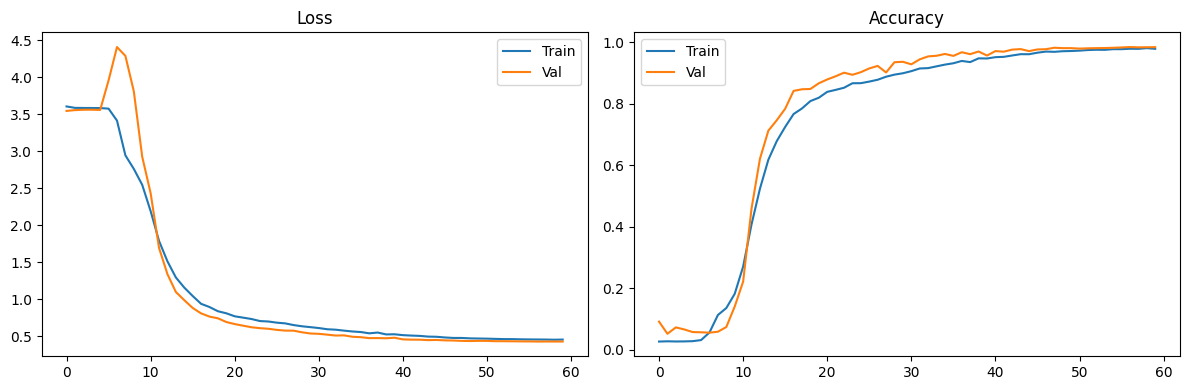

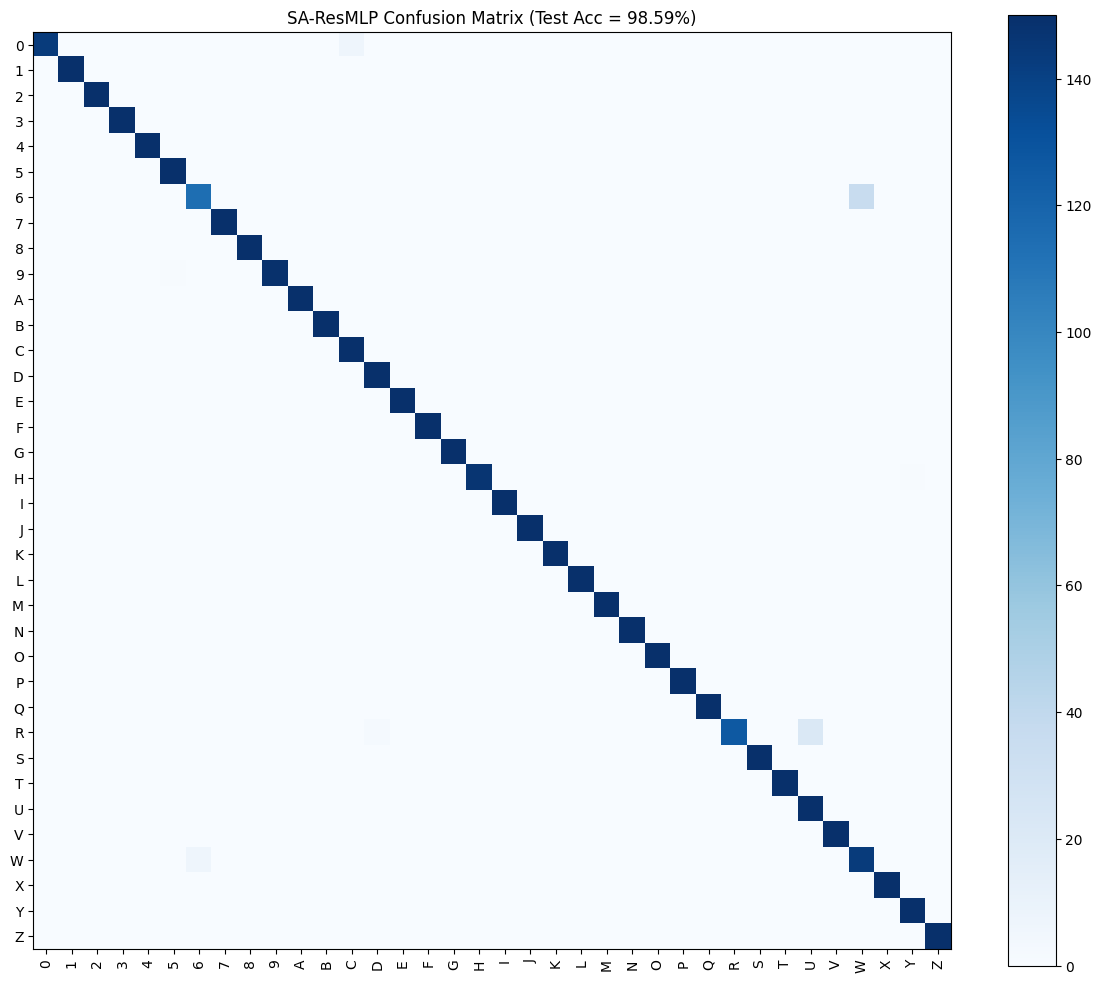

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

ckpt = torch.load(BEST_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state"])
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(device))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(yb.numpy())

test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy (36 classes): {test_acc:.4f}")
print(classification_report(y_true, y_pred, target_names=labels, digits=4))

# Vẽ biểu đồ Loss & Accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Val")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Val")
axes[1].set_title("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig(WORK_DIR / "training_curves.png", dpi=150)
plt.show()

# Vẽ Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)
plt.title(f"SA-ResMLP Confusion Matrix (Test Acc = {test_acc:.2%})")
plt.colorbar()
plt.tight_layout()
plt.savefig(WORK_DIR / "confusion_matrix.png", dpi=150)
plt.show()